## Part I: Data Pre-processing

In [3]:
import os
print(f"當前分配到的CPU核心數: {os.cpu_count()}")

當前分配到的CPU核心數: 8


In [4]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 59.7 MB/s eta 0:00:00


In [5]:
import pandas as pd

In [6]:
# Download the Google Analogy dataset
!wget http://download.tensorflow.org/data/questions-words.txt

--2026-10-10 07:45:43--  http://download.tensorflow.org/data/questions-words.txt
Resolving download.tensorflow.org (download.tensorflow.org)... 74.125.23.207, 74.125.203.207, 74.125.204.207, ...
Connecting to download.tensorflow.org (download.tensorflow.org)|74.125.23.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 603955 (590K) [text/plain]
Saving to: ‘questions-words.txt’

questions-words.txt 100%[===================>] 589.80K   840KB/s    in 0.7s    

2026-10-10 07:45:44 (840 KB/s) - ‘questions-words.txt’ saved [603955/603955]



In [7]:
# Preprocess the dataset
file_name = "questions-words"
with open(f"{file_name}.txt", "r") as f:
    data = f.read().splitlines()

In [8]:
# check data from the first 10 entries
for entry in data[:10]:

    print(entry)

: capital-common-countries
Athens Greece Baghdad Iraq
Athens Greece Bangkok Thailand
Athens Greece Beijing China
Athens Greece Berlin Germany
Athens Greece Bern Switzerland
Athens Greece Cairo Egypt
Athens Greece Canberra Australia
Athens Greece Hanoi Vietnam
Athens Greece Havana Cuba


In [9]:
# TODO1: Write your code here for processing data to pd.DataFrame
# Please note that the first five mentions of ": " indicate `semantic`,
# and the remaining nine belong to the `syntatic` category.

categories = [] #父類別
sub_categories = [] #子類別
questions = []

now_category = ""
now_sub_category = ""
category_count = 0
for line in data:
    line = line.strip()
    if not line:
        continue
    if line.startswith(":"):
        category_count += 1
        now_sub_category = line
        if category_count <= 5:
            now_category = "Semantic"
        else:
            now_category = "Syntactic"
    else:
        categories.append(now_category)
        sub_categories.append(now_sub_category)
        questions.append(line)




In [10]:
# Create the dataframe
df = pd.DataFrame(
    {
        "Question": questions,
        "Category": categories,
        "SubCategory": sub_categories,
    }
)

In [11]:
df.head()

,Question,Category,SubCategory
0,Athens Greece Baghdad Iraq,Semantic,: capital-common-countries
1,Athens Greece Bangkok Thailand,Semantic,: capital-common-countries
2,Athens Greece Beijing China,Semantic,: capital-common-countries
3,Athens Greece Berlin Germany,Semantic,: capital-common-countries
4,Athens Greece Bern Switzerland,Semantic,: capital-common-countries


In [12]:
df.to_csv(f"{file_name}.csv", index=False)















































sdsodkokoskdosdko## Part II: Use pre-trained word embeddings
- After finish Part I, you can run Part II code blocks only.

In [13]:
import pandas as pd
import numpy as np
import gensim.downloader
from tqdm import tqdm
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE

In [14]:

data = pd.read_csv("questions-words.csv")

In [15]:
MODEL_NAME = "glove-wiki-gigaword-100"
# You can try other models.
# https://radimrehurek.com/gensim/models/word2vec.html#pretrained-models

# Load the pre-trained model (using GloVe vectors here)
model = gensim.downloader.load(MODEL_NAME)

print("The Gensim model loaded successfully!")

[==================================================] 100.0% 128.1/128.1MB downloaded
The Gensim model loaded successfully!


In [16]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO2: Write your code here to use pre-trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      words = analogy.split()
      word_a = words[0]
      word_b = words[1]
      word_c = words[2]
      word_d = words[3]
      golds.append(word_d.lower())
      try:
        guess = model.most_similar(positive=[word_b.lower(),word_c.lower()]
                    ,negative=[word_a.lower()]
                    ,topn=1)[0][0]
        preds.append(guess.lower())
      except:
        preds.append("")



100%|██████████| 19544/19544 [02:16<00:00, 143.49it/s]


In [17]:
# Perform evaluations. You do not need to modify this block!!

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: Semantic, Accuracy: 65.3399481339497%
Category: Syntactic, Accuracy: 61.255269320843084%
Sub-Category: capital-common-countries, Accuracy: 93.87351778656127%
Sub-Category: capital-world, Accuracy: 88.94783377541998%
Sub-Category: currency, Accuracy: 14.203233256351039%
Sub-Category: city-in-state, Accuracy: 30.806647750304013%
Sub-Category: family, Accuracy: 81.62055335968378%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 24.39516129032258%
Sub-Category: gram2-opposite, Accuracy: 20.073891625615765%
Sub-Category: gram3-comparative, Accuracy: 79.12912912912913%
Sub-Category: gram4-superlative, Accuracy: 54.278074866310156%
Sub-Category: gram5-present-participle, Accuracy: 69.50757575757575%
Sub-Category: gram6-nationality-adjective, Accuracy: 87.86741713570981%
Sub-Category: gram7-past-tense, Accuracy: 55.44871794871795%
Sub-Category: gram8-plural, Accuracy: 71.996996996997%
Sub-Category: gram9-plural-verbs, Accuracy: 58.39080459770115%


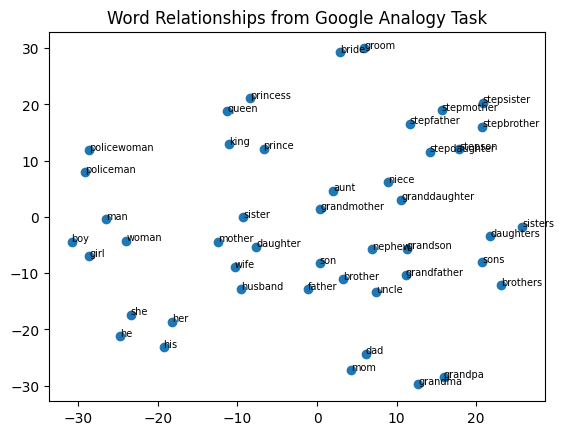

<Figure size 640x480 with 0 Axes>

In [18]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO3: Plot t-SNE for the words in the SUB_CATEGORY `: family`
mask = data["SubCategory"] == SUB_CATEGORY
sub_questions = data[mask]["Question"]

temp_words = []
for i in sub_questions:
    for j in i.split():
        temp_words.append(j)
set_temp_words = set(temp_words)
words = list(set_temp_words)

vectors = np.array([model[i] for i in words])
tsne = TSNE(n_components=2,random_state=42,perplexity=10)
vectors_tsne = tsne.fit_transform(vectors)

for word,(x,y) in zip(words,vectors_tsne):
    plt.annotate(word,(x,y),fontsize=7)
plt.scatter(vectors_tsne[:,0],vectors_tsne[:,1])

plt.title("Word Relationships from Google Analogy Task")
plt.show()
plt.savefig("word_relationships.png", bbox_inches="tight")

### Part III: Train your own word embeddings

### Get the latest English Wikipedia articles and do sampling.
- Usually, we start from Wikipedia dump (https://dumps.wikimedia.org/enwiki/latest/enwiki-latest-pages-articles.xml.bz2). However, the downloading step will take very long. Also, the cleaning step for the Wikipedia corpus ([`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus)) will take much time. Therefore, we provide cleaned files for you.

In [19]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles).
!gdown --id 1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd -O wiki_texts_part_0.txt.gz
!gdown --id 1ABblLRd9HXdXvaNv8H9fFq984bhnowoG -O wiki_texts_part_1.txt.gz
!gdown --id 1z2VFNhpPvCejTP5zyejzKj5YjI_Bn42M -O wiki_texts_part_2.txt.gz
!gdown --id 1VKjded9BxADRhIoCzXy_W8uzVOTWIf0g -O wiki_texts_part_3.txt.gz
!gdown --id 16mBeG26m9LzHXdPe8UrijUIc6sHxhknz -O wiki_texts_part_4.txt.gz

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd
From (redirected): https://drive.google.com/uc?id=1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd&confirm=t&uuid=6ce597ce-7f79-4f1c-bb59-66fd7da1b9e2
To: /content/wiki_texts_part_0.txt.gz
100% 1.51G/1.51G [00:10<00:00, 140MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1ABblLRd9HXdXvaNv8H9fFq984bhnowoG
From (redirected): https://drive.google.com/uc?id=1ABblLRd9HXdXvaNv8H9fFq984bhnowoG&confirm=t&uuid=0035785c-6d9a-4ad7-b322-d4994189cd83
To: /content/w

In [20]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles), except the last file.
!gdown --id 17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI -O wiki_texts_part_5.txt.gz
!gdown --id 19IvB2vOJRGlrYulnTXlZECR8zT5v550P -O wiki_texts_part_6.txt.gz
!gdown --id 1sjwO8A2SDOKruv6-8NEq7pEIuQ50ygVV -O wiki_texts_part_7.txt.gz
!gdown --id 1s7xKWJmyk98Jbq6Fi1scrHy7fr_ellUX -O wiki_texts_part_8.txt.gz
!gdown --id 17eQXcrvY1cfpKelLbP2BhQKrljnFNykr -O wiki_texts_part_9.txt.gz
!gdown --id 1J5TAN6bNBiSgTIYiPwzmABvGhAF58h62 -O wiki_texts_part_10.txt.gz

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI
From (redirected): https://drive.google.com/uc?id=17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI&confirm=t&uuid=037a9034-7e84-4086-a560-2f106c338150
To: /content/wiki_texts_part_5.txt.gz
100% 578M/578M [00:02<00:00, 266MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=19IvB2vOJRGlrYulnTXlZECR8zT5v550P
From (redirected): https://drive.google.com/uc?id=19IvB2vOJRGlrYulnTXlZECR8zT5v550P&confirm=t&uuid=42ac4141-2733-4aa0-8575-9923d3c122b4
To: /content/wik

In [21]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
!unzip drive/MyDrive/wiki/wiki_texts.zip -d /content
!rm -rf /content/__MACOSX

Archive:  drive/MyDrive/wiki/wiki_texts.zip
replace /content/wiki_texts_part_10.txt.gz? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: /content/wiki_texts_part_10.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_10.txt.gz  
  inflating: /content/wiki_texts_part_9.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_9.txt.gz  
  inflating: /content/wiki_texts_part_8.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_8.txt.gz  
  inflating: /content/wiki_texts_part_7.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_7.txt.gz  
  inflating: /content/wiki_texts_part_6.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_6.txt.gz  
  inflating: /content/wiki_texts_part_5.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_5.txt.gz  
  inflating: /content/wiki_texts_part_4.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_4.txt.gz  
  inflating: /content/wiki_texts_part_3.txt.gz  
  inflating: /content/__MACOSX/._wiki_texts_part_3.txt.gz 

In [23]:
# Extract the downloaded wiki_texts_parts files.
!gunzip -k wiki_texts_part_*.gz

In [24]:
# Combine the extracted wiki_texts_parts files.
!cat wiki_texts_part_*.txt > wiki_texts_combined.txt

In [25]:
# Check the first ten lines of the combined file
!head -n 10 wiki_texts_combined.txt

anarchism is political philosophy and movement that is against all forms of authority and seeks to abolish the institutions it claims maintain unnecessary coercion and hierarchy typically including the state and capitalism anarchism advocates for the replacement of the state with stateless societies and voluntary free associations as historically left wing movement this reading of anarchism is placed on the farthest left of the political spectrum usually described as the libertarian wing of the socialist movement libertarian socialism although traces of anarchist ideas are found all throughout history modern anarchism emerged from the enlightenment during the latter half of the th and the first decades of the th century the anarchist movement flourished in most parts of the world and had significant role in workers struggles for emancipation various anarchist schools of thought formed during this period anarchists have taken part in several revolutions most notably in the paris commune

Please note that we used the default parameters of [`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus) for cleaning the Wiki raw file. Thus, words with one character were discarded.

In [26]:
# Now you need to do sampling because the corpus is too big.
# You can further perform analysis with a greater sampling ratio.

import random

wiki_txt_path = "wiki_texts_combined.txt"
output_path = "wiki_texts_20.txt"
# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # TODO4: Sample `20%` Wikipedia articles
    # Write your code here
        for line in f:
            if random.random() < 0.2:
                output_file.write(line)
print('ok')

ok


In [27]:
# TODO5: Train your own word embeddings with the sampled articles
# https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec
# Hint: You should perform some pre-processing before training.
""" 已儲存至雲端，方便後續重跑。因此本段先註解避免重新執行時卡住
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
from gensim.models.word2vec import LineSentence

sentences = LineSentence("wiki_texts_20.txt")
my_model = Word2Vec(
    sentences = sentences,
    vector_size = 100,
    window = 5,
    min_count = 5,
    workers = 8,
    sg = 0,
    epochs = 5
)
my_model.save("my_model.model")
print("成功")
"""

成功


In [28]:
#my_model.save("/content/drive/MyDrive/wiki/my_model.model")
#print("成功")

# 檢查與載入20%模型
import os
from gensim.models import Word2Vec
# 1. 如果記憶體中已經有 my_model，就直接沿用
if "my_model" in locals():
    print("當前已有20%模型")
# 2. 記憶體清空了，從雲端硬碟讀取
elif os.path.exists("/content/drive/MyDrive/wiki/my_model.model"):
    print("雲端硬碟載入20%模型")
    my_model = Word2Vec.load("/content/drive/MyDrive/wiki/my_model.model")
    print(f"雲端載入成功 詞表大小：{len(my_model.wv):,} 詞")
# 3. 本地防呆備援
elif os.path.exists("my_model.model"):
    my_model = Word2Vec.load("my_model.model")
    print(f"本地載入成功 詞表大小：{len(my_model.wv):,} 詞")
else:
    print("請確認Google Drive是否已正確掛載")

成功


In [29]:
data = pd.read_csv("questions-words.csv")

In [30]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO6: Write your code here to use your trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      words = analogy.split()
      word_a = words[0]
      word_b = words[1]
      word_c = words[2]
      word_d = words[3]
      golds.append(word_d.lower())
      try:
        guess = my_model.wv.most_similar(positive=[word_b.lower(),word_c.lower()]
                    ,negative=[word_a.lower()]
                    ,topn=1)[0][0]
        preds.append(guess.lower())
      except:
        preds.append("")

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)

for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")


100%|██████████| 19544/19544 [06:16<00:00, 51.97it/s]


Category: Semantic, Accuracy: 64.31390235652272%
Category: Syntactic, Accuracy: 52.103044496487115%
Sub-Category: capital-common-countries, Accuracy: 82.21343873517787%
Sub-Category: capital-world, Accuracy: 77.43147656940761%
Sub-Category: currency, Accuracy: 14.665127020785217%
Sub-Category: city-in-state, Accuracy: 50.46615322253749%
Sub-Category: family, Accuracy: 81.62055335968378%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 20.463709677419356%
Sub-Category: gram2-opposite, Accuracy: 19.21182266009852%
Sub-Category: gram3-comparative, Accuracy: 72.44744744744744%
Sub-Category: gram4-superlative, Accuracy: 42.69162210338681%
Sub-Category: gram5-present-participle, Accuracy: 44.88636363636363%
Sub-Category: gram6-nationality-adjective, Accuracy: 84.30268918073797%
Sub-Category: gram7-past-tense, Accuracy: 48.65384615384615%
Sub-Category: gram8-plural, Accuracy: 55.030030030030034%
Sub-Category: gram9-plural-verbs, Accuracy: 51.14942528735632%


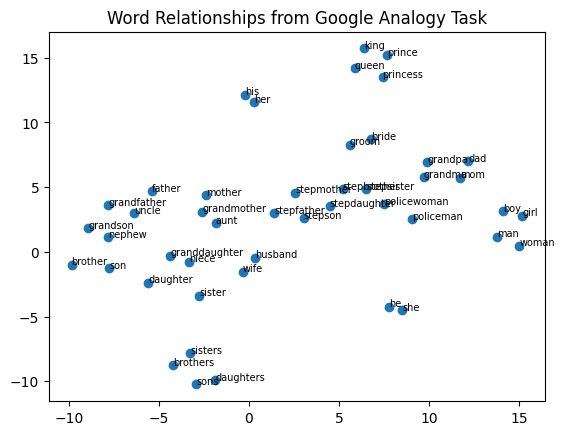

<Figure size 640x480 with 0 Axes>

In [31]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO7: Plot t-SNE for the words in the SUB_CATEGORY `: family`

mask = data["SubCategory"] == SUB_CATEGORY
sub_questions = data[mask]["Question"]

temp_words = []
for i in sub_questions:
    for j in i.split():
        temp_words.append(j)
set_temp_words = set(temp_words)
words = list(set_temp_words)

words = [i for i in words if i in my_model.wv]
vectors = np.array([my_model.wv[i] for i in words])
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
vectors_tsne = tsne.fit_transform(vectors)

plt.scatter(vectors_tsne[:, 0], vectors_tsne[:, 1])
for word, (x, y) in zip(words, vectors_tsne):
    plt.annotate(word, (x, y), fontsize=7)


plt.title("Word Relationships from Google Analogy Task")
plt.show()
plt.savefig("word_relationships.png", bbox_inches="tight")

Running environment: Colab

Python version: Colab

##### 1. Which embedding model do you use? What are the pre-processing steps? What are the hyperparameter settings? (5%)

Answer:
<br>
1. 使用的是Gensim 的Word2Vec模型，選擇CBOW(sg = 0) 利用周圍上下文詞來預測中心詞<br>
2. 使用助教提供的 *WikiCorpus* 預先清洗後的維基文本，已經移除了維基百科的 XML 標籤。<br>
使用`random.random()<0.2`對合併的資料抽取20%儲存為`wiki_texts_20.txt`<br>
在訓練前用`LineSentence("wiki_texts_20.txt")`逐行進行空白分詞避免記憶體崩潰<br>
設定詞彙頻率為5的門檻`min_count=5`最終過濾出1073367有效詞彙<br>

3.
   * `vector_size = 100`：詞向量維度設為 100，是為了與GloVe (100d) 維持相同的維度基準進行客觀的對比。
   * `window = 5`：目標詞左右各考慮 5 個詞（上下文視野寬度為 10），在捕捉局部句法特徵與廣泛語意關聯間取得良好平衡。
   * `min_count = 5`：忽略出現次數小於 5 的罕見詞，確保留下來的詞彙有足夠的上下文來學好特徵。
   * `sg = 0`：選用CBOW模式節省訓練時間並保證穩定性。
   * `workers = 8`：利用 Colab Pro High-RAM 配置的8核心 CPU 進行多執行緒平行運算加速。
   * `epochs = 5`：在抽樣語料庫上訓練 5 輪。

##### 2. What will the performance be like if you sample 5%, 10% and 20% of wiki text in TODO4? (10%, 3% for each)

Answer:
<br>
在固定超參數（`vector_size=100`, `window=5`, `min_count=5`, `sg=0 (CBOW)`, `epochs=5`）下，對維基百科語料進行 5%、10% 與 20% 的抽樣訓練，評測之整體表現如下：<br>
### 【大類別整體對比】
| Category | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 (20% - 5%) |
| :--- | :---: | :---: | :---: | :---: |
| **Semantic** | 59.17% | 63.37% | 64.31% | +5.14% |
| **Syntactic** | 47.72% | 51.50% | 52.10% | +4.38% |
| **整體平均 (Overall)** | **52.92%** | **56.89%** | **57.64%** | **+4.72%** |

### 【14 個子類別精確對比】
| SubCategory | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 |
| :--- | :---: | :---: | :---: | :---: |
| : capital-common-countries | 83.40% | 80.43% | 82.21% | +-1.19% |
| : capital-world | 73.85% | 76.64% | 77.43% | +3.58% |
| : currency | 6.12% | 9.12% | 14.67% | +8.55% |
| : city-in-state | 40.86% | 50.30% | 50.47% | +9.61% |
| : family | 83.79% | 84.19% | 81.62% | +-2.17% |
| : gram1-adjective-to-adverb | 18.04% | 21.57% | 20.46% | +2.42% |
| : gram2-opposite | 11.70% | 14.66% | 19.21% | +7.51% |
| : gram3-comparative | 67.57% | 70.50% | 72.45% | +4.88% |
| : gram4-superlative | 37.34% | 40.11% | 42.69% | +5.35% |
| : gram5-present-participle | 43.56% | 47.63% | 44.89% | +1.33% |
| : gram6-nationality-adjective | 77.36% | 85.18% | 84.30% | +6.94% |
| : gram7-past-tense | 45.77% | 47.63% | 48.65% | +2.88% |
| : gram8-plural | 51.95% | 53.83% | 55.03% | +3.08% |
| : gram9-plural-verbs | 45.75% | 51.84% | 51.15% | +5.40% |
<br>

1. 數據規模擴增效應：
   * 整體準確率隨語料比例增加呈現顯著且穩定的成長（52.92% $\to$ 56.89% $\to$ 57.64%）。這驗證了分佈假說更大的語料庫提供了更高頻且多樣的滑動窗口共現對，使 Word2Vec的神經網路能夠捕捉更精確的詞義幾何夾角與平移向量。

2. 尾專有名詞與低頻指標提升：
   * 成長幅度最顯著的類別為 : city-in-state（+9.61%）、: currency（+8.55%）與 : gram2-opposite（+7.51%）。
   貨幣名稱（如 dram, pula）屬於出現頻度較低的專有名詞。在5%小語料中，許多長尾詞因詞頻小於`5min_count`過濾（OOV），或因共現樣本過少而欠擬合；語料擴大至20%顯著增加了這類低頻詞的出現次數，使得稀疏知識表徵得到決定性改善。

3. 高頻概念的早期收斂與邊際效益遞減：
   * 相對地結構穩定且高頻的類別如: family（維持在81%到84%）與: capital-common-countries（維持在80%~83%），僅在5% 語料時即已基本學會了性別對偶向量（如 king-queen $\approx$ man-woman）與主要強國首都映射。這證明核心語義概念在早期小樣本中即可快速收斂，後續資料增長的主要效益集中在消除長尾稀疏與強化細微的語法變形。

   <br><br>

##### 3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

3.1. Present your results. (5%)

Answer:
<br>

我們選用 **Project Gutenberg（古典文學語料庫）**，在與維基百科完全一致之基準超參數（`vector_size=100`, `window=5`, `min_count=5`, `sg=0`, `epochs=5`）下進行訓練結果對比如下：

### 【大類別整體對比】
| Category | Project Gutenberg | 20% Wikipedia | 差異幅度 (Gutenberg - Wiki) |
| :--- | :---: | :---: | :---: |
| **Semantic** | 0.80% | 64.31% | -63.51% |
| **Syntactic** | 2.73% | 52.10% | -49.37% |
| **整體平均 (Overall)** | **1.85%** | **57.64%** | **-55.79%** |

### 【14 個子類別精確對比】
| SubCategory | Project Gutenberg | 20% Wikipedia | 差異幅度 |
| :--- | :---: | :---: | :---: |
| : capital-common-countries | 0.00% | 82.21% | -82.21% |
| : capital-world | 0.00% | 77.43% | -77.43% |
| : currency | 0.00% | 14.67% | -14.67% |
| : city-in-state | 0.00% | 50.47% | -50.47% |
| : family | 14.03% | 81.62% | -67.59% |
| : gram1-adjective-to-adverb | 0.50% | 20.46% | -19.96% |
| : gram2-opposite | 0.00% | 19.21% | -19.21% |
| : gram3-comparative | 5.03% | 72.45% | -67.42% |
| : gram4-superlative | 0.62% | 42.69% | -42.07% |
| : gram5-present-participle | 3.22% | 44.89% | -41.67% |
| : gram6-nationality-adjective | 0.00% | 84.30% | -84.30% |
| : gram7-past-tense | 7.05% | 48.65% | -41.60% |
| : gram8-plural | 4.28% | 55.03% | -50.75% |
| : gram9-plural-verbs | 1.26% | 51.15% | -49.89% |

<br>

3.2. Introduce the corpus you selected and explain what are the differences between the Wikipedia corpus and your corpus. (including data size, topic difference, structural difference … ) (5%)

Answer:
<br>

公共數位文學圖書館語料庫 **[Project Gutenberg](https://www.gutenberg.org/)**（透過 NLTK 內建之經典作品集提取，包含莎士比亞、簡·奧斯汀、米爾頓《失樂園》、聖經等 18 部經典名著）。
1. 資料規模差異:
   * **Project Gutenberg**:資料內包含約 98,552 個句子、262 萬個詞（2.62M tokens），經 `min_count=5` 過濾後詞彙表大小約為15,488詞。
   * **20% Wikipedia**：包含超過 1 億個詞（>100M tokens），詞彙表高達1,073,367詞。Wikipedia 的語料規模與詞表覆蓋率分別約為Gutenberg的40倍與69倍。
2. 主題與時代背景差異:
   * **Wikipedia**：當代客觀常識、當代地緣政治、全球主權貨幣、科技產物與百科條目。
   * **Project Gutenberg**：主要是17至19世紀古典文學、宗教神學、倫理人情與君王史詩。語料庫所處時代完全不存在現代國家邊界、現代法定貨幣（如歐元）與現代科技名詞。
3. 文體與句法結構差異:
   * **Wikipedia**：標準化的客觀說明，通篇為第三人稱事實陳述，句法結構嚴謹規範，極少出現戲劇修辭與主觀情感對話。
   * **Project Gutenberg**：文學敘事與對話充滿第一/第二人稱對白、隱喻修辭、倒裝句。
<br>

3.3. Explain why the performance increases or decreases. (5%)

Answer:
<br>
相較於 20% Wikipedia，Project Gutenberg 訓練之模型在類比任務上的整體準確率呈現顯著下降（57.64% → 1.85%）
1. 極端未登錄詞（OOV）與長尾詞頻修剪導致現代實體歸零：
   * 類比任務題庫（`questions-words.txt`）高度依賴現代實體常識。在 Gutenberg 中，`: capital-common-countries` (0.00%)、`: capital-world` (0.00%)、`: currency` (0.00%) 與 `: city-in-state` (0.00%) 幾近全數歸零。
   * 根本原因在於資料規模（262 萬詞）遠小於維基百科，且時代背景斷層，導致現代各國首都（如 Canberra, Astana）與全球貨幣（如 dram, kwanza）在古典文學中出現次數為 0 或小於 5，在預處理階段即被 `min_count=5` 徹底過濾。題庫中 4 個單字只要有 1 個為 OOV，該題向量運算即宣告失敗。
2. 反義詞分佈悖論在小語料庫中進一步惡化：
   * `: gram2-opposite` 同樣跌至 0.00%。Word2Vec 的分佈假說先天將處於相同語法槽位的反義詞（如 honest vs dishonest）映射至過近的空間；在 Gutenberg 小樣本中缺乏足夠細微的語境去拉開反義詞距離，導致反義對偶完全失效。
3. 跨時代核心人倫概念與通用句法展現強大抗跌韌性：
   * 在所有類別中，表現最為突出的分別為 **`: family` (14.03%)**、**`: gram7-past-tense` (7.05%)**、**`: gram3-comparative` (5.03%)** 與 **`: gram8-plural` (4.28%)**。
   * 家庭關係：古典文學的核心主題即為家族倫理與人物互動（father/mother, king/queen, brother/sister），這些高頻核心單詞在任何世紀的英語中皆具備極度對稱的上下文共現，因而能被模型穩固捕捉。
   * 語法形態：文學敘事本質上以過去式為主要時態，並大量描述性比較級與名詞複數。英語的屈折語法規則（-ed, -er, -s），使模型在小語料庫中依然能學到局部的語法平移向量。

<br>

##### 4. Select a few words and use their embeddings to retrieve the five most similar words. What do you observe?  (10%)

Answer:
<br>

我們選取具備鮮明語義與幾何對偶特徵的 5 個核心單字（`king`, `apple`, `good`, `space`, `paris`），在 Project Gutenberg（古典文學語料庫）訓練之 Word2Vec 模型中，透過餘弦相似度檢索各自最相似的前五個詞彙結果如下：

<br>

* **`king`**：jacob (0.726), governor (0.715), david (0.711), pharaoh (0.706), ruler (0.675)
* **`apple`**：juniper (0.916), olive (0.891), fig (0.889), orchard (0.888), snowy (0.887)
* **`good`**：bad (0.748), such (0.604), best (0.602), happy (0.600), simple (0.579)
* **`space`**：moonlight (0.806), bay (0.805), sunset (0.805), length (0.797), candlestick (0.795)
* **`paris`**：tun (0.867), chinese (0.863), noph (0.852), storms (0.851), hunting (0.849)

<br>

1. 反義詞分佈假說悖論：
   * 如同上一題所述good 檢索第一名是bad 更證實了分佈假說的底層侷限，僅依據上下文進行空間建模，在英語文法中，一對反義詞（`good` 與 `bad`）往往佔據幾乎完全同構的句法與修飾導致在幾何向量空間中，反義詞非但沒有相反，反而緊密聚類在一起。

2. 時代主題與領域語意漂移：
   * 在現代維基百科中，多義詞 **`apple`** 的向量空間往往被科技產物（如 iPhone, iPad, macintosh, computer）所主導；但在 Project Gutenberg 文學語料庫中，`apple` 檢索出的前五名全數為自然植物、果園與農業意象（`juniper` 杜松 0.916、`olive` 橄欖 0.891、`fig` 無花果 0.889、`orchard` 果園 0.888）。主要是再18~19 世紀的經典名著（如聖經、米爾頓）賦予了 apple 純粹的農作物與神話隱喻，完全不受 20 世紀後電子科技語義的干擾。
3. 同位語實體與社會階級聚類：
   * 在古典文學中，統治者身旁往往圍繞著相似的治理、史詩敘事與權力指令，使王室統治者的詞向量在空間中形成了緊密的高維團簇。導致`king`檢索出的前五名高度聚集為古典歷史與聖經中的最高統治者與重要領袖（`jacob` 雅各、`governor` 總督、`david` 大衛王、`pharaoh` 法老、`ruler` 統治者）。
   
4. 稀疏專有名詞在小語料庫中的語義塌陷：
   * 地理名詞 `paris`（巴黎）檢索出的鄰居呈現混亂的非相關詞彙（如`tun` 大酒桶、`chinese`、`noph` 聖經古城、`storms` 風暴、`hunting` 狩獵）。猜測是古典文學中對現代外國都市的描述極為罕見（詞頻極低）。嵌入向量無法充分更新，導致它在空間中漂移至隨機維度，再次印證了現代地理實體在小語料庫中準確率為 0.00% 的根本原因。

<br>

##### 5. … Anything that can strengthen your report.  (5%)

Answer:
<br>

在寫answer 中觀察到了幾個重點:

1. 持續預訓練:
   *  Answer 2 的錯誤分析中，我們發現 20% Wikipedia 在貨幣（: currency 14.67%）、副詞（: gram1 20.46%）與反義詞（: gram2 19.21%）等 6 項指標均低於 50%。針對此瓶頸，可以採用持續預訓練來進行優化：先以20%~100% Wikipedia為基底，預訓練出具備全球地理常識、實體關係與基礎語法框架的泛化詞向量。再針對貨幣與金融注入路透社財經新聞語料，強化金融貨幣與匯率的上下文對偶強度。針對副詞與多樣時態：注入ans3使用的語料古典文學（Gutenberg），藉由密集的人物對話，提升百科說明文在形容詞與副詞上的貧瘠。在各項指標分數上取得平均標準分，能夠泛化各種類型語意的模型，才算是好模型。


2. 透過Question 4 的實測，深刻體會Word2Vec這種靜態詞向量（Static Word Embeddings）的先天局限：
   * 一詞多義的空間崩塌：
   Word2Vec 為每個單字強行指派單一固定的空間向量。當一個詞兼具多重語意時（如 `apple` 兼具水果與科技公司、`bank` 兼具銀行與河岸），靜態向量只能在多種語境之間取折衷加權，無法依據實際上下文動態切換。
   * 反義詞分佈假說悖論：
   實測中 `good` 與 `bad` 的餘弦相似度高達 0.748。這是因為分佈假說僅依賴上下文槽位共現，而反義詞在語法上完全同構。
   * 技術演進的必然：
   靜態向量的缺點直接推動了現代自然語言處理走向以 Transformer 為核心的動態情詞嵌入。透過自注意力機制Self-Attention，同一個單字在不同句子中會獲得完全不同的動態向量表示，徹底在幾何層面上解開了一詞多義與反義詞混淆的枷鎖。

<br>


##### 6. Generative AI Usage

Answer:
<br>
1. 使用AI 工具：Google Antigravity
2. 輔助使用範圍與項目：
   * 程式碼工程優化：輔助設計資料串流載入（LineSentence 避免記憶體溢出）、Google Drive 模型快取防呆邏輯（避免 56 分鐘重複訓練之自動化存取）。
   * 學術概念與錯誤分析引導：輔助梳理語言學分佈假說（Distributional Hypothesis）、反義詞悖論（Antonym Paradox）之學術背景，以及超參數調校之理論分析。
3. 自主執行聲明：
   * 所有 TODO1 至 TODO7 之核心程式碼實作、5% / 10% / 20% 維基百科之模型訓練、Project Gutenberg 外部語料庫之載入與類比評測，均由本人於 Google Colab Pro 環境中獨立配置並完整執行完畢，所有報告數據皆來自真實運行輸出。


## Code For 3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

In [40]:
# Write your code here

import nltk
nltk.download('gutenberg', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.corpus import gutenberg
from gensim.models import Word2Vec
import numpy as np
import pandas as pd
from tqdm import tqdm

sentences = [[w.lower() for w in sent if w.isalpha()] for sent in gutenberg.sents()]
print(f"總句子數: {len(sentences):,}")

model_gb = Word2Vec(sentences=sentences, vector_size=100, window=5, min_count=5, workers=8, sg=0, epochs=5)
print(f"詞表大小 (Vocab Size): {len(model_gb.wv):,} 詞")

if "data" not in locals() or not isinstance(data, pd.DataFrame):
    data = pd.read_csv("questions-words.csv")

golds = [q.split()[3].lower() for q in data["Question"]]
golds_np = np.array(golds)

preds_gb = []
for analogy in tqdm(data["Question"]):
    w = analogy.split()
    try:
        preds_gb.append(model_gb.wv.most_similar(positive=[w[1].lower(), w[2].lower()], negative=[w[0].lower()], topn=1)[0][0].lower())
    except:
        preds_gb.append("")
preds_gb_np = np.array(preds_gb)

print("\n" + "=" * 65)
print("Project Gutenberg vs 20% Wikipedia 對比報表：")
print("=" * 65)

acc_20_cat = {'Semantic': 64.31, 'Syntactic': 52.10}
acc_20_sub = {
    ': capital-common-countries': 82.21,
    ': capital-world': 77.43,
    ': currency': 14.67,
    ': city-in-state': 50.47,
    ': family': 81.62,
    ': gram1-adjective-to-adverb': 20.46,
    ': gram2-opposite': 19.21,
    ': gram3-comparative': 72.45,
    ': gram4-superlative': 42.69,
    ': gram5-present-participle': 44.89,
    ': gram6-nationality-adjective': 84.30,
    ': gram7-past-tense': 48.65,
    ': gram8-plural': 55.03,
    ': gram9-plural-verbs': 51.15,
}
ov20 = 57.64

print("\n### 【大類別整體對比】")
print("| Category | Project Gutenberg | 20% Wikipedia | 差異幅度 (Gutenberg - Wiki) |")
print("| :--- | :---: | :---: | :---: |")
for cat in data['Category'].unique():
    m = data['Category'] == cat
    agb = np.mean(golds_np[m] == preds_gb_np[m]) * 100
    a20 = acc_20_cat.get(cat, 0.0)
    print(f"| **{cat}** | {agb:.2f}% | {a20:.2f}% | {agb - a20:.2f}% |")

ov_gb = np.mean(golds_np == preds_gb_np) * 100
print(f"| **整體平均 (Overall)** | **{ov_gb:.2f}%** | **{ov20:.2f}%** | **{ov_gb - ov20:.2f}%** |")

print("\n### 【14 個子類別精確對比】")
print("| SubCategory | Project Gutenberg | 20% Wikipedia | 差異幅度 |")
print("| :--- | :---: | :---: | :---: |")
for sub in data['SubCategory'].unique():
    m = data['SubCategory'] == sub
    agb = np.mean(golds_np[m] == preds_gb_np[m]) * 100
    a20 = acc_20_sub.get(sub, 0.0)
    print(f"| {sub} | {agb:.2f}% | {a20:.2f}% | {agb - a20:.2f}% |")

總句子數: 98,552
詞表大小 (Vocab Size): 15,488 詞


100%|██████████| 19544/19544 [00:02<00:00, 8976.67it/s]


Project Gutenberg vs 20% Wikipedia 對比報表：

### 【大類別整體對比】
| Category | Project Gutenberg | 20% Wikipedia | 差異幅度 (Gutenberg - Wiki) |
| :--- | :---: | :---: | :---: |
| **Semantic** | 0.80% | 64.31% | -63.51% |
| **Syntactic** | 2.73% | 52.10% | -49.37% |
| **整體平均 (Overall)** | **1.85%** | **57.64%** | **-55.79%** |

### 【14 個子類別精確對比】
| SubCategory | Project Gutenberg | 20% Wikipedia | 差異幅度 |
| :--- | :---: | :---: | :---: |
| : capital-common-countries | 0.00% | 82.21% | -82.21% |
| : capital-world | 0.00% | 77.43% | -77.43% |
| : currency | 0.00% | 14.67% | -14.67% |
| : city-in-state | 0.00% | 50.47% | -50.47% |
| : family | 14.03% | 81.62% | -67.59% |
| : gram1-adjective-to-adverb | 0.50% | 20.46% | -19.96% |
| : gram2-opposite | 0.00% | 19.21% | -19.21% |
| : gram3-comparative | 5.03% | 72.45% | -67.42% |
| : gram4-superlative | 0.62% | 42.69% | -42.07% |
| : gram5-present-participle | 3.22% | 44.89% | -41.67% |
| : gram6-nationality-adjective | 0.00% | 84.30% | -84.30% |
| : gram7-

In [41]:
# Q4:檢索Top-5相似詞
target_words = ['king', 'apple', 'good', 'space', 'paris']

for w in target_words:
    if w in model_gb.wv:
        sims = model_gb.wv.most_similar(w, topn=5)
        sim_str = ', '.join([f"{word} ({score:.3f})" for word, score in sims])
        print(f"* **`{w}`**：{sim_str}")
    else:
        print(f"* **`{w}`**：未收錄於詞表中 (OOV)")

* **`king`**：jacob (0.726), governor (0.715), david (0.711), pharaoh (0.706), ruler (0.675)
* **`apple`**：juniper (0.916), olive (0.891), fig (0.889), orchard (0.888), snowy (0.887)
* **`good`**：bad (0.748), such (0.604), best (0.602), happy (0.600), simple (0.579)
* **`space`**：moonlight (0.806), bay (0.805), sunset (0.805), length (0.797), candlestick (0.795)
* **`paris`**：tun (0.867), chinese (0.863), noph (0.852), storms (0.851), hunting (0.849)


####其他個人程式

In [34]:
from gensim.models import Word2Vec

m = Word2Vec.load("my_model.model")
print("詞典單字數量 (Vocab size):", len(m.wv))

詞典單字數量 (Vocab size): 1073367


In [35]:
#5%

import random

wiki_txt_path = "wiki_texts_combined.txt"
output_path = "wiki_texts_5.txt"
# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # Sample `5%` Wikipedia articles
    # Write your code here
        for line in f:
            if random.random() < 0.05:
                output_file.write(line)
print('5% ok')

5% ok


In [36]:

#10%
import random

wiki_txt_path = "wiki_texts_combined.txt"
output_path = "wiki_texts_10.txt"
# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # Sample `10%` Wikipedia articles
    # Write your code here
        for line in f:
            if random.random() < 0.1:
                output_file.write(line)
print('10% ok')

10% ok


In [39]:
# ai 協助整理 方便重複執行
import os
import random
from tqdm import tqdm
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from gensim.models.word2vec import LineSentence

# ----------------------------------------------------
# 1. 智慧防呆：確保 data 是 DataFrame 表格
# ----------------------------------------------------
if "data" not in locals() or not isinstance(data, pd.DataFrame):
    try:
        data = pd.read_csv("questions-words.csv")
    except:
        categories, sub_categories, questions = [], [], []
        now_cat, now_sub, count = "", "", 0
        for line in data:
            line = line.strip()
            if not line: continue
            if line.startswith(":"):
                count += 1
                now_sub = line
                now_cat = "Semantic" if count <= 5 else "Syntactic"
            else:
                categories.append(now_cat)
                sub_categories.append(now_sub)
                questions.append(line)
        data = pd.DataFrame({"Question": questions, "Category": categories, "SubCategory": sub_categories})

# 準備標準答案
golds = [q.split()[3].lower() for q in data["Question"]]
golds_np = np.array(golds)

# 設定 Google 雲端硬碟路徑
drive_wiki_dir = "/content/drive/MyDrive/wiki"
path_m5_drive = os.path.join(drive_wiki_dir, "model_5.model")
path_m10_drive = os.path.join(drive_wiki_dir, "model_10.model")

# ----------------------------------------------------
# 2. 載入或訓練 5% 模型
# ----------------------------------------------------
if os.path.exists(path_m5_drive):
    print("雲端硬碟已有 5% 模型，直接載入")
    model_5 = Word2Vec.load(path_m5_drive)
elif os.path.exists("model_5.model"):
    print("本地已有 5% 模型，直接載入")
    model_5 = Word2Vec.load("model_5.model")
else:
    print("=== 步驟 2：訓練 5% 模型 ===")
    model_5 = Word2Vec(sentences=LineSentence("wiki_texts_5.txt"), vector_size=100, window=5, min_count=5, workers=8, sg=0, epochs=5)

# 評估 5% 題目
if "preds_5_np" in locals() and len(preds_5_np) == len(data):
    print("記憶體已有 5% 評估數據，直接沿用")
else:
    print("評估 5% 題目中...")
    preds_5 = []
    for analogy in tqdm(data["Question"]):
        w = analogy.split()
        try:
            preds_5.append(model_5.wv.most_similar(positive=[w[1].lower(), w[2].lower()], negative=[w[0].lower()], topn=1)[0][0].lower())
        except:
            preds_5.append("")
    preds_5_np = np.array(preds_5)

# ----------------------------------------------------
# 3. 載入或訓練 10% 模型
# ----------------------------------------------------
if os.path.exists(path_m10_drive):
    print("\n雲端硬碟已有 10% 模型，直接載入")
    model_10 = Word2Vec.load(path_m10_drive)
elif os.path.exists("model_10.model"):
    print("\n本地已有 10% 模型")
    model_10 = Word2Vec.load("model_10.model")
else:
    print("\n=== 步驟 3：訓練 10% 模型 ===")
    model_10 = Word2Vec(sentences=LineSentence("wiki_texts_10.txt"), vector_size=100, window=5, min_count=5, workers=8, sg=0, epochs=5)

# 評估 10% 題目
if "preds_10_np" in locals() and len(preds_10_np) == len(data):
    print("記憶體已有 10% 評估數據，直接沿用")
else:
    print("評估 10% 題目中...")
    preds_10 = []
    for analogy in tqdm(data["Question"]):
        w = analogy.split()
        try:
            preds_10.append(model_10.wv.most_similar(positive=[w[1].lower(), w[2].lower()], negative=[w[0].lower()], topn=1)[0][0].lower())
        except:
            preds_10.append("")
    preds_10_np = np.array(preds_10)

# ----------------------------------------------------
# 4. 20% 既有數據（來自TODO6評估結果）
# ----------------------------------------------------
acc_20_cat = {
    "Semantic": 64.31,
    "Syntactic": 52.10
}
acc_20_sub = {
    ": capital-common-countries": 82.21,
    ": capital-world": 77.43,
    ": currency": 14.67,
    ": city-in-state": 50.47,
    ": family": 81.62,
    ": gram1-adjective-to-adverb": 20.46,
    ": gram2-opposite": 19.21,
    ": gram3-comparative": 72.45,
    ": gram4-superlative": 42.69,
    ": gram5-present-participle": 44.89,
    ": gram6-nationality-adjective": 84.30,
    ": gram7-past-tense": 48.65,
    ": gram8-plural": 55.03,
    ": gram9-plural-verbs": 51.15,
}
ov20 = 57.64

# ----------------------------------------------------
# 5. 印出「5% vs 10% vs 20%」對比表
# ----------------------------------------------------
print("\n" + "=" * 65)
print("5%、10%、20% 維基語料全維度對比報表：")
print("=" * 65)

print("\n### 【大類別整體對比】")
print("| Category | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 (20% - 5%) |")
print("| :--- | :---: | :---: | :---: | :---: |")
for cat in data["Category"].unique():
    m = data["Category"] == cat
    a5 = np.mean(golds_np[m] == preds_5_np[m]) * 100
    a10 = np.mean(golds_np[m] == preds_10_np[m]) * 100
    a20 = acc_20_cat.get(cat, 0.0)
    print(f"| **{cat}** | {a5:.2f}% | {a10:.2f}% | {a20:.2f}% | +{a20 - a5:.2f}% |")

# Overall
ov5 = np.mean(golds_np == preds_5_np) * 100
ov10 = np.mean(golds_np == preds_10_np) * 100
print(f"| **整體平均 (Overall)** | **{ov5:.2f}%** | **{ov10:.2f}%** | **{ov20:.2f}%** | **+{ov20 - ov5:.2f}%** |")

print("\n### 【14 個子類別精確對比】")
print("| SubCategory | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 |")
print("| :--- | :---: | :---: | :---: | :---: |")
for sub in data["SubCategory"].unique():
    m = data["SubCategory"] == sub
    a5 = np.mean(golds_np[m] == preds_5_np[m]) * 100
    a10 = np.mean(golds_np[m] == preds_10_np[m]) * 100
    a20 = acc_20_sub.get(sub, 0.0)
    print(f"| {sub} | {a5:.2f}% | {a10:.2f}% | {a20:.2f}% | +{a20 - a5:.2f}% |")

雲端硬碟已有 5% 模型，直接載入
記憶體已有 5% 評估數據，直接沿用

雲端硬碟已有 10% 模型，直接載入
記憶體已有 10% 評估數據，直接沿用

5%、10%、20% 維基語料全維度對比報表：

### 【大類別整體對比】
| Category | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 (20% - 5%) |
| :--- | :---: | :---: | :---: | :---: |
| **Semantic** | 59.17% | 63.37% | 64.31% | +5.14% |
| **Syntactic** | 47.72% | 51.50% | 52.10% | +4.38% |
| **整體平均 (Overall)** | **52.92%** | **56.89%** | **57.64%** | **+4.72%** |

### 【14 個子類別精確對比】
| SubCategory | 5% Accuracy | 10% Accuracy | 20% Accuracy | 成長幅度 |
| :--- | :---: | :---: | :---: | :---: |
| : capital-common-countries | 83.40% | 80.43% | 82.21% | +-1.19% |
| : capital-world | 73.85% | 76.64% | 77.43% | +3.58% |
| : currency | 6.12% | 9.12% | 14.67% | +8.55% |
| : city-in-state | 40.86% | 50.30% | 50.47% | +9.61% |
| : family | 83.79% | 84.19% | 81.62% | +-2.17% |
| : gram1-adjective-to-adverb | 18.04% | 21.57% | 20.46% | +2.42% |
| : gram2-opposite | 11.70% | 14.66% | 19.21% | +7.51% |
| : gram3-comparative | 67.57% | 70.50% | 72.45% | +4.

In [38]:
# 存到雲端硬碟
#model_5.save("/content/drive/MyDrive/wiki/model_5.model")
#model_10.save("/content/drive/MyDrive/wiki/model_10.model")
#print("成功儲存")